# Full fine-tuning: 144-minute experiment
Run from the top in a fresh A100 GPU session. This notebook starts from pretrained weights, with no smoke test. Each run writes to a unique Drive folder, preserving your previous 0.610 experiment. Training timing includes data loading and periodic logging/checkpointing; a final batch can slightly exceed the limit. Latency and validation prediction generation are recorded separately from training.

Outputs: model checkpoint, per-step loss CSV, loss-curve PNG, experiment-summary JSON, raw latency CSV, validation TXT/ZIP. Training configuration is unchanged except for the time limit and logging. CodaBench accuracy must be entered after submission.


The linear classifier is initialised with class prototypes computed from training images only, using the pretrained backbone and evaluation preprocessing. Image features are L2-normalised, averaged per class, and the class means are L2-normalised before copying into the head; biases are set to zero. The head and backbone are then fine-tuned as before. Prototype extraction is separate from the unchanged 144-minute training budget.


# Download data

In [ ]:
%pip install -U huggingface_hub

!hf download doem1997/cs604-course-data \
  --repo-type dataset \
  --local-dir /content/cs604-course-data

!tar -xzf /content/cs604-course-data/train.tar.gz -C /content/cs604-course-data
!tar -xzf /content/cs604-course-data/val.tar.gz -C /content/cs604-course-data

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 838.0/838.0 kB 51.2 MB/s eta 0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.31.0
    Uninstalling huggingface_hub-1.31.0:
      Successfully uninstalled huggingface_hub-1.31.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.27.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 2.1.1 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.1.1 which is incompatible.
transformers 5.17.0 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 2.1.1 which is incompatible.
tokenizers 0.23.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.1.1 which is incompatible.
gradio-client 2.7.0 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.1.1 which

# Full fine-tuning baseline

In [ ]:
# Install packages and check paths
%pip install -U timm

from pathlib import Path

ROOT = Path("/content/cs604-course-data")
assert (ROOT / "train.txt").is_file()
assert (ROOT / "val.txt").is_file()
assert (ROOT / "train").is_dir()
assert (ROOT / "val").is_dir()

print("Dataset found at:", ROOT)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 103.3 MB/s eta 0:00:00
  Attempting uninstall: timm
    Found existing installation: timm 1.0.29
    Uninstalling timm-1.0.29:
      Successfully uninstalled timm-1.0.29
Dataset found at: /content/cs604-course-data


In [ ]:
# build the dataset and model
import random
import time
import torch
import timm

from PIL import Image
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda"
assert torch.cuda.is_available(), "Select a GPU runtime first"

MODEL_NAME = "hf_hub:timm/vit_base_patch16_224.augreg2_in21k_ft_in1k"

model = timm.create_model(
    MODEL_NAME,
    pretrained=True,
    num_classes=10_000,
).to(DEVICE)

# Full fine-tuning: every parameter, including the new head, is trainable.
assert all(p.requires_grad for p in model.parameters())

data_config = timm.data.resolve_model_data_config(model)

# prepares training images at the model's expected size and applies random augmentation
train_transform = timm.data.create_transform(
    **data_config, is_training=True
)

# prepares validation images consistently, without random training augmentation
eval_transform = timm.data.create_transform(
    **data_config, is_training=False
)

class TrainDataset(Dataset):
    def __init__(self, root, label_file, transform):
        self.root = root
        self.transform = transform
        self.rows = []

        with label_file.open() as f:
            for line in f:
                path, class_id = line.strip().split()
                self.rows.append((path, int(class_id)))

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        path, class_id = self.rows[index]
        with Image.open(self.root / path) as image:
            x = self.transform(image.convert("RGB"))
        return x, class_id

train_dataset = TrainDataset(ROOT, ROOT / "train.txt", train_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
)

print("Training images:", len(train_dataset))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

# Initialise the existing linear head with class prototypes from TRAINING data only.
# Keep the architecture and all parameters trainable for full fine-tuning.
# Evaluation preprocessing avoids random augmentation during prototype extraction.
import torch.nn.functional as F

prototype_dataset = TrainDataset(ROOT, ROOT / "train.txt", eval_transform)
prototype_loader = DataLoader(
    prototype_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    generator=torch.Generator().manual_seed(SEED),
)

head = model.get_classifier()
assert isinstance(head, nn.Linear)
prototype_sums = torch.zeros(head.out_features, head.in_features, device=DEVICE)
prototype_counts = torch.zeros(head.out_features, device=DEVICE, dtype=torch.long)
prototype_start = time.monotonic()
was_training = model.training
model.eval()

try:
    # Preserve training RNG state and avoid changing backbone weights.
    with torch.random.fork_rng(devices=[torch.cuda.current_device()]), torch.no_grad():
        for batch_idx, (images, labels) in enumerate(prototype_loader, start=1):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            assert bool(((labels >= 0) & (labels < head.out_features)).all()), "Invalid class ID"
            with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
                features = model.forward_head(model.forward_features(images), pre_logits=True)
            # Average unit-length image features, then normalise each class mean.
            features = F.normalize(features.float(), dim=1)
            prototype_sums.index_add_(0, labels, features)
            prototype_counts.index_add_(0, labels, torch.ones_like(labels))
            if batch_idx % 100 == 0:
                print(f"Prototype batches: {batch_idx}/{len(prototype_loader)}")

        missing = (prototype_counts == 0).nonzero(as_tuple=True)[0]
        assert missing.numel() == 0, f"Classes without training images: {missing.cpu().tolist()}"
        prototypes = prototype_sums / prototype_counts.unsqueeze(1)
        assert bool((prototypes.norm(dim=1) > 0).all()), "A class prototype has zero norm"
        prototypes = F.normalize(prototypes, dim=1)
        head.weight.copy_(prototypes.to(dtype=head.weight.dtype))
        if head.bias is not None:
            head.bias.zero_()
finally:
    model.train(was_training)

torch.cuda.synchronize()
prototype_seconds = time.monotonic() - prototype_start
print(f"Initialised {head.out_features} class prototypes in {prototype_seconds / 60:.1f} minutes")
del prototype_sums, prototype_counts, prototypes, features, images, labels


config.json:   0%|          | 0.00/588 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Training images: 450000
Trainable parameters: 93488656
Prototype batches: 100/14063
Prototype batches: 200/14063
Prototype batches: 300/14063
Prototype batches: 400/14063
Prototype batches: 500/14063
Prototype batches: 600/14063
Prototype batches: 700/14063
Prototype batches: 800/14063
Prototype batches: 900/14063
Prototype batches: 1000/14063
Prototype batches: 1100/14063
Prototype batches: 1200/14063
Prototype batches: 1300/14063
Prototype batches: 1400/14063
Prototype batches: 1500/14063
Prototype batches: 1600/14063
Prototype batches: 1700/14063
Prototype batches: 1800/14063
Prototype batches: 1900/14063
Prototype batches: 2000/14063
Prototype batches: 2100/14063
Prototype batches: 2200/14063
Prototype batches: 2300/14063
Prototype batches: 2400/14063
Prototype batches: 2500/14063
Prototype batches: 2600/14063
Prototype batches: 2700/14063
Prototype batches: 2800/14063
Prototype batches: 2900/14063
Prototype batches: 3000/14063
Prototype batches: 3100/14063
Prototype batches: 3200/

In [ ]:
# Train a fresh full fine-tuning experiment for 144 minutes
from google.colab import drive

drive.mount("/content/drive")

import csv
import json
import platform
from datetime import datetime, timezone

RUN_ID = "full_finetuning_144min_" + datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
SAVE_DIR = Path("/content/drive/MyDrive/CS604") / RUN_ID
SAVE_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT = SAVE_DIR / "full_finetune_vit_b16.pt"

MAX_TRAIN_SECONDS = 144 * 60
LOSS_CSV = SAVE_DIR / "training_loss.csv"
SUMMARY_JSON = SAVE_DIR / "experiment_summary.json"
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
gpu = torch.cuda.get_device_properties(0)
summary = {
    "run_id": RUN_ID, "method": "Full fine-tuning", "model": MODEL_NAME,
    "seed": SEED, "training_images": len(train_dataset),
    "head_initialization": "L2-normalized class means of L2-normalized training features; zero bias",
    "prototype_initialization_seconds": prototype_seconds,
    "batch_size": train_loader.batch_size, "num_workers": train_loader.num_workers,
    "total_parameters_including_head": total_params,
    "trainable_parameters_including_head": trainable_params,
    "trainable_percent_of_total_including_head": 100 * trainable_params / total_params,
    "gpu_name": gpu.name, "gpu_count_used": 1,
    "gpu_capacity_GiB": gpu.total_memory / 1024**3,
    "training_limit_minutes": 144, "precision": "bf16 autocast",
    "optimizer": "AdamW", "backbone_lr": 1e-5, "head_lr": 1e-3,
    "weight_decay": 0.05, "scheduler": None,
    "loss": "CrossEntropyLoss, mean over batch", "data_config": data_config,
    "train_transform": str(train_transform), "eval_transform": str(eval_transform),
    "torch_version": str(torch.__version__), "timm_version": timm.__version__,
    "python_version": platform.python_version(),
    "checkpoint": str(CHECKPOINT), "codabench_score": None,
    "codabench_submission_id": None,
}
def save_summary():
    SUMMARY_JSON.write_text(json.dumps(summary, indent=2, default=str))
save_summary()

criterion = nn.CrossEntropyLoss()

# Let the prototype-initialised classifier learn faster than the backbone.
head = model.get_classifier()
head_ids = {id(p) for p in head.parameters()}

optimizer = torch.optim.AdamW(
    [
        {
            "params": [p for p in model.parameters() if id(p) not in head_ids],
            "lr": 1e-5,
        },
        {
            "params": list(head.parameters()),
            "lr": 1e-3,
        },
    ],
    weight_decay=0.05,
)

model.train()
torch.cuda.reset_peak_memory_stats()
start = time.monotonic()
last_save = start
step = 0
loss_log = []

samples_seen = 0
log_file = LOSS_CSV.open("w", newline="")
writer = csv.writer(log_file)
writer.writerow(["step", "epoch", "elapsed_seconds", "batch_size", "loss", "backbone_lr", "head_lr"])
epoch = 0
while time.monotonic() - start < MAX_TRAIN_SECONDS:
    epoch += 1
    for images, labels in train_loader:
        if time.monotonic() - start >= MAX_TRAIN_SECONDS:
            break

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # A100 supports bf16 mixed precision.
        with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
            logits = model(images)
            loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        step += 1
        loss_value = float(loss.item())
        loss_log.append((step, loss_value))
        samples_seen += len(labels)
        writer.writerow([step, epoch, time.monotonic() - start, len(labels), loss_value,
                         optimizer.param_groups[0]["lr"], optimizer.param_groups[1]["lr"]])

        if step % 100 == 0:
            log_file.flush()
            elapsed = time.monotonic() - start
            print(f"Step {step} | loss {loss.item():.4f} | {elapsed/60:.1f} min")

        # Save periodically in case Colab disconnects.
        if time.monotonic() - last_save >= 30 * 60:
            torch.save(model.state_dict(), CHECKPOINT)
            last_save = time.monotonic()
            print("Checkpoint saved")

    if time.monotonic() - start >= MAX_TRAIN_SECONDS:
        break

torch.cuda.synchronize()
log_file.close()
elapsed = time.monotonic() - start
peak_gb = torch.cuda.max_memory_allocated() / 1024**3

print(f"Steps: {step}")
print(f"Training time: {elapsed/60:.1f} minutes")
print(f"Peak PyTorch GPU memory: {peak_gb:.2f} GiB")

torch.save(model.state_dict(), CHECKPOINT)
summary.update({
    "steps": step, "samples_seen": samples_seen,
    "effective_epochs": samples_seen / len(train_dataset),
    "training_seconds": elapsed, "training_minutes": elapsed / 60,
    "training_GPU_hours": elapsed / 3600,
    "peak_PyTorch_allocated_GiB": peak_gb,
    "peak_PyTorch_reserved_GiB": torch.cuda.max_memory_reserved() / 1024**3,
    "loss_csv": str(LOSS_CSV),
})
save_summary()
print("Final checkpoint:", CHECKPOINT)
print("Experiment summary:", SUMMARY_JSON)

Mounted at /content/drive
Step 100 | loss 3.6764 | 0.1 min
Step 200 | loss 4.7181 | 0.2 min
Step 300 | loss 5.1648 | 0.3 min
Step 400 | loss 4.8226 | 0.4 min
Step 500 | loss 4.9576 | 0.5 min
Step 600 | loss 4.4882 | 0.6 min
Step 700 | loss 3.5898 | 0.7 min
Step 800 | loss 4.4121 | 0.8 min
Step 900 | loss 3.6891 | 0.8 min
Step 1000 | loss 5.5454 | 0.9 min
Step 1100 | loss 3.9705 | 1.0 min
Step 1200 | loss 3.8081 | 1.1 min
Step 1300 | loss 3.8887 | 1.2 min
Step 1400 | loss 4.2358 | 1.3 min
Step 1500 | loss 3.4919 | 1.4 min
Step 1600 | loss 3.5320 | 1.5 min
Step 1700 | loss 4.2050 | 1.6 min
Step 1800 | loss 3.9109 | 1.7 min
Step 1900 | loss 3.5643 | 1.8 min
Step 2000 | loss 2.9835 | 1.9 min
Step 2100 | loss 3.2056 | 2.0 min
Step 2200 | loss 3.9139 | 2.1 min
Step 2300 | loss 3.2622 | 2.2 min
Step 2400 | loss 3.4576 | 2.2 min
Step 2500 | loss 3.4128 | 2.3 min
Step 2600 | loss 2.8645 | 2.4 min
Step 2700 | loss 3.0997 | 2.5 min
Step 2800 | loss 3.6175 | 2.6 min
Step 2900 | loss 3.8753 | 2.7 m

In [ ]:
# generate validation predictions
from zipfile import ZipFile, ZIP_DEFLATED

class ValDataset(Dataset):
    def __init__(self, root, path_file, transform):
        self.root = root
        self.transform = transform
        self.paths = path_file.read_text().splitlines()

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        with Image.open(self.root / path) as image:
            x = self.transform(image.convert("RGB"))
        return x, path

val_dataset = ValDataset(ROOT, ROOT / "val.txt", eval_transform)
val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
)

model.eval()
predictions = []

with torch.inference_mode():
    for images, paths in val_loader:
        images = images.to(DEVICE, non_blocking=True)

        with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
            logits = model(images)

        class_ids = logits.argmax(dim=1).cpu().tolist()
        predictions.extend(zip(paths, class_ids))

assert len(predictions) == 50_000
assert len({path for path, _ in predictions}) == 50_000
assert all(0 <= class_id < 10_000 for _, class_id in predictions)

TEAM_NUMBER = "08"
txt_path = SAVE_DIR / f"val_team_{TEAM_NUMBER}.txt"
zip_path = SAVE_DIR / f"val_team_{TEAM_NUMBER}.zip"

with txt_path.open("w") as f:
    for path, class_id in predictions:
        f.write(f"{path} {class_id}\n")

with ZipFile(zip_path, "w", ZIP_DEFLATED) as zf:
    zf.write(txt_path, arcname=txt_path.name)

print("Submission:", zip_path)
print("Lines:", len(predictions))
summary.update({"validation_prediction_lines": len(predictions), "validation_txt": str(txt_path), "validation_zip": str(zip_path)})
save_summary()


Submission: /content/drive/MyDrive/CS604/full_finetuning_144min_20261002_064808/val_team_08.zip
Lines: 50000


## Required training loss curve
Raw per-batch loss is saved to CSV during training; the smoothed line is for readability only.


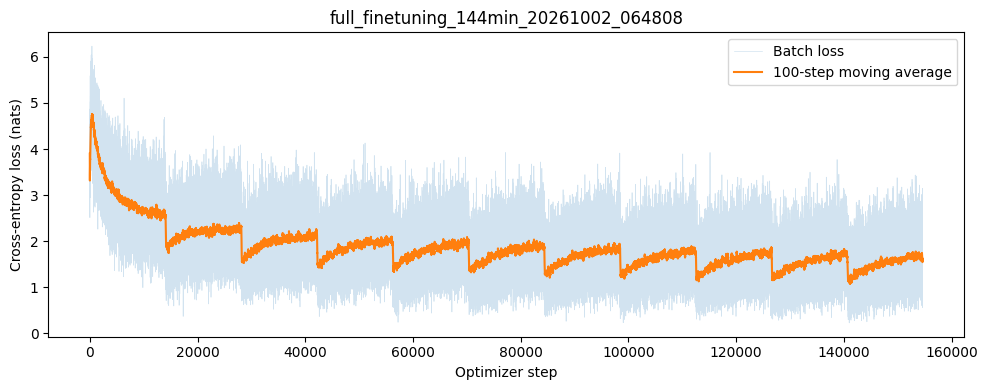

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
loss_df = pd.read_csv(LOSS_CSV)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(loss_df["step"], loss_df["loss"], alpha=0.2, linewidth=0.5, label="Batch loss")
ax.plot(loss_df["step"], loss_df["loss"].rolling(100, min_periods=1).mean(), label="100-step moving average")
ax.set(xlabel="Optimizer step", ylabel="Cross-entropy loss (nats)", title=RUN_ID)
ax.legend()
fig.tight_layout()
curve_path = SAVE_DIR / "training_loss_curve.png"
fig.savefig(curve_path, dpi=180)
plt.show()
summary["loss_curve"] = str(curve_path)
save_summary()


## Inference latency
Batch size 1, bf16, 30 warm-ups, 200 repetitions. Measures GPU forward pass only, excluding loading, preprocessing, and transfer. Use the same conditions for every method. This cell loads the saved checkpoint.


In [ ]:
import numpy as np
model.load_state_dict(torch.load(CHECKPOINT, map_location="cpu", weights_only=True))
model.eval()
image = val_dataset[0][0].unsqueeze(0).to(DEVICE)
latencies = []
start_event = torch.cuda.Event(enable_timing=True)
end_event = torch.cuda.Event(enable_timing=True)
with torch.inference_mode(), torch.autocast(device_type="cuda", dtype=torch.bfloat16):
    for _ in range(30):
        _ = model(image)
    torch.cuda.synchronize()
    for _ in range(200):
        start_event.record()
        _ = model(image)
        end_event.record()
        end_event.synchronize()
        latencies.append(start_event.elapsed_time(end_event))
latency_csv = SAVE_DIR / "inference_latency.csv"
with latency_csv.open("w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["repetition", "latency_ms"])
    w.writerows(enumerate(latencies, 1))
summary["inference_latency"] = {
    "mean_ms_per_image": float(np.mean(latencies)),
    "median_ms_per_image": float(np.median(latencies)),
    "p95_ms_per_image": float(np.percentile(latencies, 95)),
    "batch_size": 1, "warmup_runs": 30, "timed_runs": 200,
    "gpu": torch.cuda.get_device_name(0), "precision": "bf16 autocast",
    "scope": "GPU model forward only", "raw_csv": str(latency_csv),
}
save_summary()
print(json.dumps(summary["inference_latency"], indent=2))


{
  "mean_ms_per_image": 7.157775361537933,
  "median_ms_per_image": 6.986752033233643,
  "p95_ms_per_image": 8.664422464370723,
  "batch_size": 1,
  "warmup_runs": 30,
  "timed_runs": 200,
  "gpu": "NVIDIA A100-SXM4-80GB",
  "precision": "bf16 autocast",
  "scope": "GPU model forward only",
  "raw_csv": "/content/drive/MyDrive/CS604/full_finetuning_144min_20261002_064808/inference_latency.csv"
}
